In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import torch
import torch.nn as nn
import joblib
import shap
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve)
from scipy.sparse import hstack
from torch.utils.data import DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ── Paths ──────────────────────────────────────────────────
PREP_PATH  = "/kaggle/input/notebooks/catalinagligor22/02-preprocessing/"   # Output from Notebook 02
TRAIN_PATH = "/kaggle/input/notebooks/catalinagligor22/03-training/"        # Output from Notebook 03
OUTPUT_DIR = "/kaggle/working/"

# ── Load data ──────────────────────────────────────────────
X_test_img  = np.load(PREP_PATH + 'X_test_img.npy')
y_test_img  = np.load(PREP_PATH + 'y_test_img.npy')
X_val_img   = np.load(PREP_PATH + 'X_val_img.npy')
y_val_img   = np.load(PREP_PATH + 'y_val_img.npy')

df_test     = pd.read_csv(PREP_PATH + 'clinical_test.csv')
df_val      = pd.read_csv(PREP_PATH + 'clinical_val.csv')

preprocessor = joblib.load(PREP_PATH + 'preprocessor.pkl')
tfidf        = joblib.load(PREP_PATH + 'tfidf_vectorizer.pkl')
xgb          = joblib.load(TRAIN_PATH + 'xgboost_model.pkl')
lr_model     = joblib.load(TRAIN_PATH + 'logistic_regression.pkl')

print("✅ Data and models loaded!")
print(f"   Test images:   {X_test_img.shape}")
print(f"   Test patients: {len(df_test)}")

✅ Data and models loaded!
   Test images:   (660, 256, 256)
   Test patients: 10271


In [15]:
# Redifining Attention U-Net architecture (same as notebook 03_training)
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, 1, bias=False),
            nn.BatchNorm2d(F_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, 1, bias=False),
            nn.BatchNorm2d(F_int)
        )
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, 1, bias=True),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi


class AttentionUNet(nn.Module):
    def __init__(self, features=[64, 128, 256, 512]):
        super().__init__()
        self.encoders = nn.ModuleList()
        self.pools = nn.ModuleList()

        in_ch = 1
        for f in features:
            self.encoders.append(DoubleConv(in_ch, f))
            self.pools.append(nn.MaxPool2d(2))
            in_ch = f

        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)

        self.upconvs = nn.ModuleList()
        self.attentions = nn.ModuleList()
        self.decoders = nn.ModuleList()

        for f in reversed(features):
            self.upconvs.append(nn.ConvTranspose2d(f * 2, f, 2, stride=2))
            self.attentions.append(AttentionGate(F_g=f, F_l=f, F_int=f // 2))
            self.decoders.append(DoubleConv(f * 2, f))

        self.output = nn.Conv2d(features[0], 1, 1)

    def forward(self, x):
        skips = []
        for enc, pool in zip(self.encoders, self.pools):
            x = enc(x)
            skips.append(x)
            x = pool(x)

        x = self.bottleneck(x)
        skips = skips[::-1]

        for up, att, dec, skip in zip(self.upconvs, self.attentions, self.decoders, skips):
            x = up(x)
            if x.shape[-2:] != skip.shape[-2:]:
                x = nn.functional.interpolate(
                    x, size=skip.shape[-2:], mode="bilinear", align_corners=False
                )
            skip = att(g=x, x=skip)
            x = torch.cat([skip, x], dim=1)
            x = dec(x)

        return torch.sigmoid(self.output(x))


# Load the saved weights
attn_unet = AttentionUNet().to(device)
attn_unet.load_state_dict(torch.load(TRAIN_PATH + 'attention_unet_best.pth', map_location=device))
attn_unet.eval()
print(" Uploaded Attention U-Net!")

 Uploaded Attention U-Net!


**U-NET Model Performance Evaluation**

The performance of the U-Net model is evaluated on the test set using two standard metrics for image segmentation: Dice Score and IoU. 

In [16]:
def dice_score(pred, target, threshold=0.5, smooth=1e-6):
    pred_bin = (pred > threshold).float()
    inter = (pred_bin * target).sum()
    return ((2. * inter + smooth) / (pred_bin.sum() + target.sum() + smooth)).item()

def iou_score(pred, target, threshold=0.5, smooth=1e-6):
    pred_bin = (pred > threshold).float()
    inter = (pred_bin * target).sum()
    union = pred_bin.sum() + target.sum() - inter
    return ((inter + smooth) / (union + smooth)).item()

test_imgs_t = torch.tensor(X_test_img, dtype=torch.float32).unsqueeze(1).to(device)
test_masks_t = torch.tensor(y_test_img, dtype=torch.float32).unsqueeze(1)

all_dices, all_ious = [], []

with torch.no_grad():
    batch_size = 16
    for i in range(0, len(test_imgs_t), batch_size):
        batch = test_imgs_t[i:i+batch_size]
        preds = attn_unet(batch).cpu()
        masks = test_masks_t[i:i+batch_size]
        for p, m in zip(preds, masks):
            all_dices.append(dice_score(p, m))
            all_ious.append(iou_score(p, m))

mean_dice = np.mean(all_dices)
mean_iou = np.mean(all_ious)

print("=" * 40)
print(" Attention U-Net Evaluation — TEST SET")
print("=" * 40)
print(f" Dice Score : {mean_dice:.4f}")
print(f" IoU Score : {mean_iou:.4f}")
print("=" * 40)

 Attention U-Net Evaluation — TEST SET
 Dice Score : 0.9653
 IoU Score : 0.9347


## The model achieved:
#### * A Dice Score of 0.9653, which measures the degree of overlap between the predicted mask and the ground-truth mask.
#### * An IoU of 0.9347, which represents the ratio between the intersection and the union of the two masks.
 
##### The high values of these metrics indicate highly accurate segmentation and confirm that the model generalizes well to unseen data.

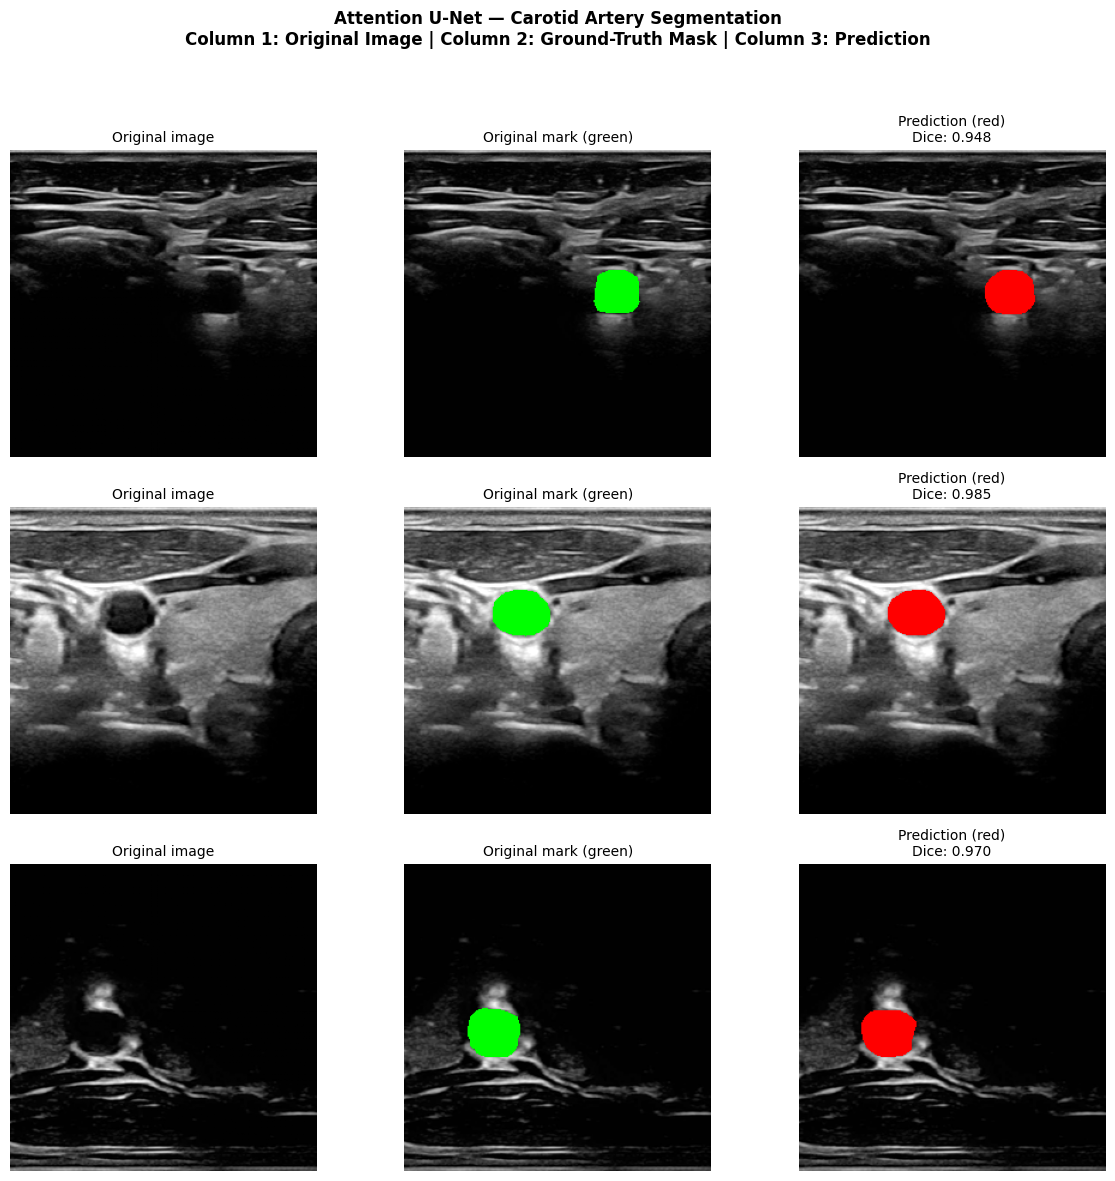

In [17]:
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
fig.suptitle(
    'Attention U-Net — Carotid Artery Segmentation\n'
    'Column 1: Original Image | Column 2: Ground-Truth Mask | Column 3: Prediction',
    fontweight='bold',
    fontsize=12
)

indices = [0, 50, 100]

with torch.no_grad():
    for row, i in enumerate(indices):
        img = test_imgs_t[i:i+1]
        pred = attn_unet(img).cpu().squeeze().numpy()
        true = y_test_img[i]
        image = X_test_img[i]

        pred_bin = (pred > 0.5).astype(np.float32)

        axes[row, 0].imshow(image, cmap='gray')
        axes[row, 0].set_title('Original image', fontsize=10)
        axes[row, 0].axis('off')

        true_overlay = np.stack([image, image, image], axis=-1)
        true_overlay[true > 0.5] = [0.0, 1.0, 0.0]
        axes[row, 1].imshow(true_overlay)
        axes[row, 1].set_title('Original mark (green)', fontsize=10)
        axes[row, 1].axis('off')

        pred_overlay = np.stack([image, image, image], axis=-1)
        pred_overlay[pred_bin > 0.5] = [1.0, 0.0, 0.0]
        axes[row, 2].imshow(pred_overlay)
        dice = dice_score(torch.tensor(pred), torch.tensor(true))
        axes[row, 2].set_title(f'Prediction (red)\nDice: {dice:.3f}', fontsize=10)
        axes[row, 2].axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(OUTPUT_DIR + 'attentionunet_predictions_colored.png', dpi=150)
plt.show()


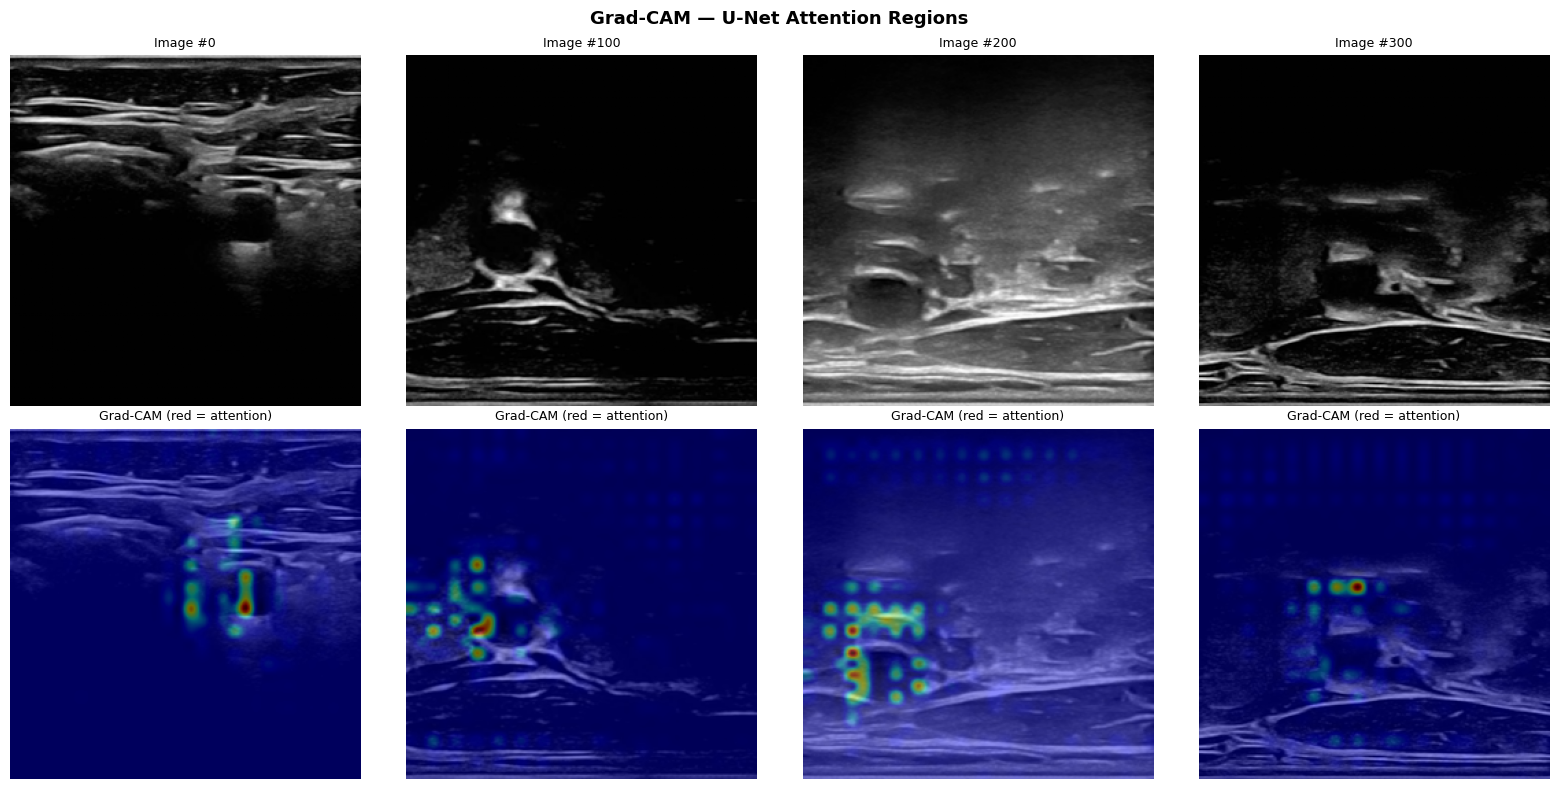

✅ Grad-CAM saved!


In [18]:
from PIL import Image as PILImage

def get_gradcam(model, image_tensor):
    """Grad-CAM on the last U-Net encoder block."""
    gradients  = []
    activations = []

    # Hook on the last encoder (features[-1] = 512 channels)
    target_layer = model.encoders[-1]

    def forward_hook(module, input, output):
        activations.append(output.detach())

    def backward_hook(module, grad_input, grad_output):
        gradients.append(grad_output[0].detach())

    fh = target_layer.register_forward_hook(forward_hook)
    bh = target_layer.register_backward_hook(backward_hook)

    # Enable gradients and temporarily switch the model to train mode
    model.train()
    output = model(image_tensor)
    model.zero_grad()
    output.mean().backward()
    model.eval()

    fh.remove()
    bh.remove()

    grad  = gradients[0].cpu().numpy()[0].mean(axis=0)   # channel-wise mean
    activ = activations[0].cpu().numpy()[0].mean(axis=0)
    cam   = np.maximum(grad * activ, 0)
    cam   = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    # Resize to 256x256
    cam_resized = np.array(PILImage.fromarray(cam).resize((256, 256)))
    return cam_resized

# Grad-CAM visualization on 4 examples
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Grad-CAM — U-Net Attention Regions', fontweight='bold', fontsize=13)

for i, idx in enumerate([0, 100, 200, 300]):
    # The image tensor must have requires_grad=True
    img_t = torch.tensor(X_test_img[idx:idx+1],
                         dtype=torch.float32).unsqueeze(0).to(device)
    # Shape: (1, 1, 256, 256)
    img_t = img_t.squeeze(0).requires_grad_(True)

    cam = get_gradcam(attn_unet, img_t.unsqueeze(0))

    axes[0, i].imshow(X_test_img[idx], cmap='gray')
    axes[0, i].set_title(f'Image #{idx}', fontsize=9)
    axes[0, i].axis('off')

    axes[1, i].imshow(X_test_img[idx], cmap='gray')
    axes[1, i].imshow(cam, cmap='jet', alpha=0.45)
    axes[1, i].set_title('Grad-CAM (red = attention)', fontsize=9)
    axes[1, i].axis('off')

plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'gradcam.png', dpi=150)
plt.show()
print("✅ Grad-CAM saved!")

## What can we observe? 
* The model does not focus on the entire image - its attention is concentrated only on the region of interest.
* The attention appears near the artery or along its boundaries, suggesting that the model has learned to use relevant features for segmentation.
* There are also attention spots in areas that appear less relevant. Grad-CAM is not perfect; it only shows the relative contribution of different regions in the image.


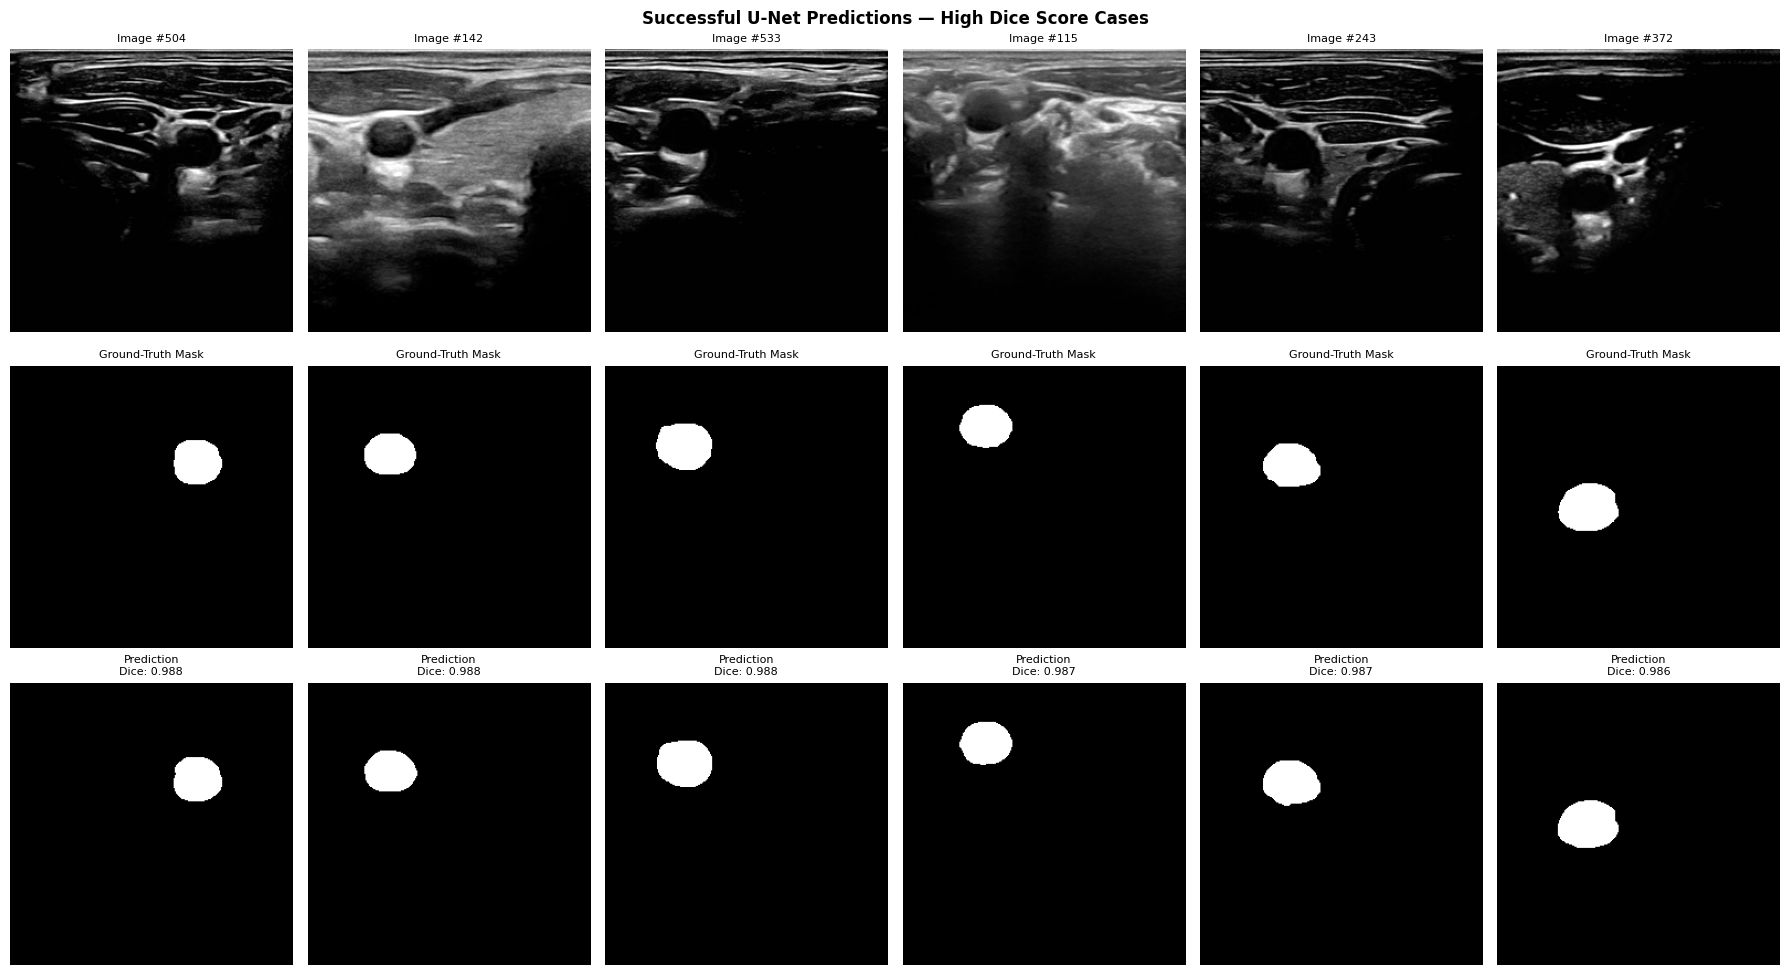

✅ Best predictions saved!


In [19]:
# Top 6 Predictions (Highest Dice Scores)
high_dice_indices = np.argsort(all_dices)[-6:][::-1]

fig, axes = plt.subplots(3, 6, figsize=(18, 10))
fig.suptitle('Successful U-Net Predictions — High Dice Score Cases',
             fontweight='bold', fontsize=12)

with torch.no_grad():
    for col, idx in enumerate(high_dice_indices):
        img  = test_imgs_t[idx:idx+1]
        pred = attn_unet(img).cpu().squeeze().numpy()
        true = y_test_img[idx]

        # Row 1: original image
        axes[0, col].imshow(X_test_img[idx], cmap='gray')
        axes[0, col].set_title(f'Image #{idx}', fontsize=8)
        axes[0, col].axis('off')

        # Row 2: ground-truth mask
        axes[1, col].imshow(true, cmap='gray')
        axes[1, col].set_title('Ground-Truth Mask', fontsize=8)
        axes[1, col].axis('off')

        # Row 3: model prediction
        axes[2, col].imshow(pred > 0.5, cmap='gray')
        axes[2, col].set_title(f'Prediction\nDice: {all_dices[idx]:.3f}', fontsize=8)
        axes[2, col].axis('off')

plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'best_predictions.png', dpi=150)
plt.show()
print("✅ Best predictions saved!")

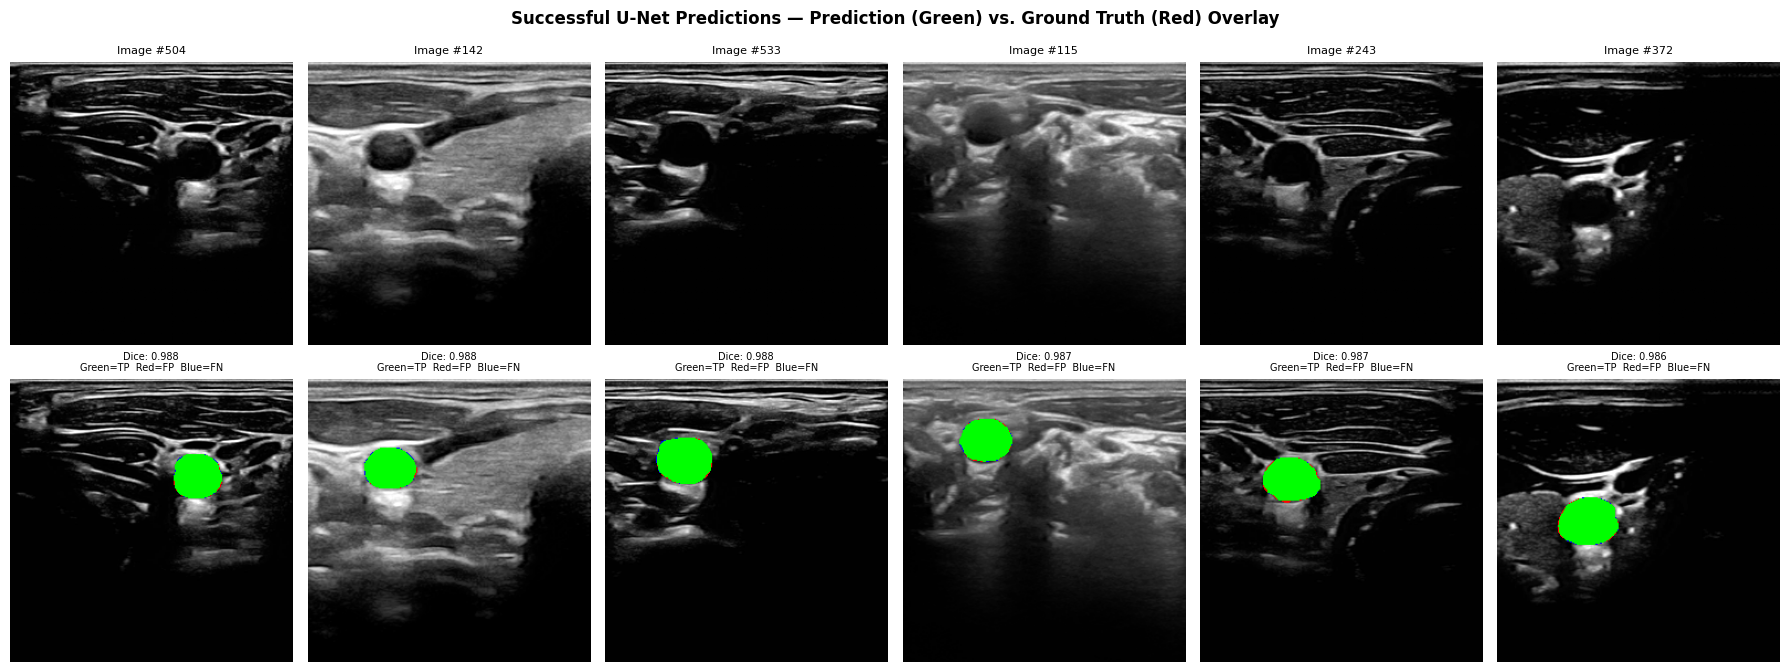

✅ Prediction overlay saved!


In [20]:
high_dice_indices = np.argsort(all_dices)[-6:][::-1]

fig, axes = plt.subplots(2, 6, figsize=(18, 7))
fig.suptitle('Successful U-Net Predictions — Prediction (Green) vs. Ground Truth (Red) Overlay',
             fontweight='bold', fontsize=12)

with torch.no_grad():
    for col, idx in enumerate(high_dice_indices):
        img  = test_imgs_t[idx:idx+1]
        pred = (attn_unet(img).cpu().squeeze().numpy() > 0.5).astype(float)
        true = y_test_img[idx]

        # Row 1: original image
        axes[0, col].imshow(X_test_img[idx], cmap='gray')
        axes[0, col].set_title(f'Image #{idx}', fontsize=8)
        axes[0, col].axis('off')

        # Row 2: color overlay
        # Green = true positive, Red = false positive, Blue = false negative
        overlay = np.stack([X_test_img[idx]] * 3, axis=-1)

        tp = (pred == 1) & (true == 1)   # correct prediction → green
        fp = (pred == 1) & (true == 0)   # false positive → red
        fn = (pred == 0) & (true == 1)   # false negative → blue

        overlay[tp, 0] = 0.0
        overlay[tp, 1] = 1.0
        overlay[tp, 2] = 0.0

        overlay[fp, 0] = 1.0
        overlay[fp, 1] = 0.0
        overlay[fp, 2] = 0.0

        overlay[fn, 0] = 0.0
        overlay[fn, 1] = 0.0
        overlay[fn, 2] = 1.0

        axes[1, col].imshow(overlay)
        axes[1, col].set_title(
            f'Dice: {all_dices[idx]:.3f}\n'
            f'Green=TP  Red=FP  Blue=FN',
            fontsize=7
        )
        axes[1, col].axis('off')

plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'best_predictions_overlay.png', dpi=150)
plt.show()
print("✅ Prediction overlay saved!")

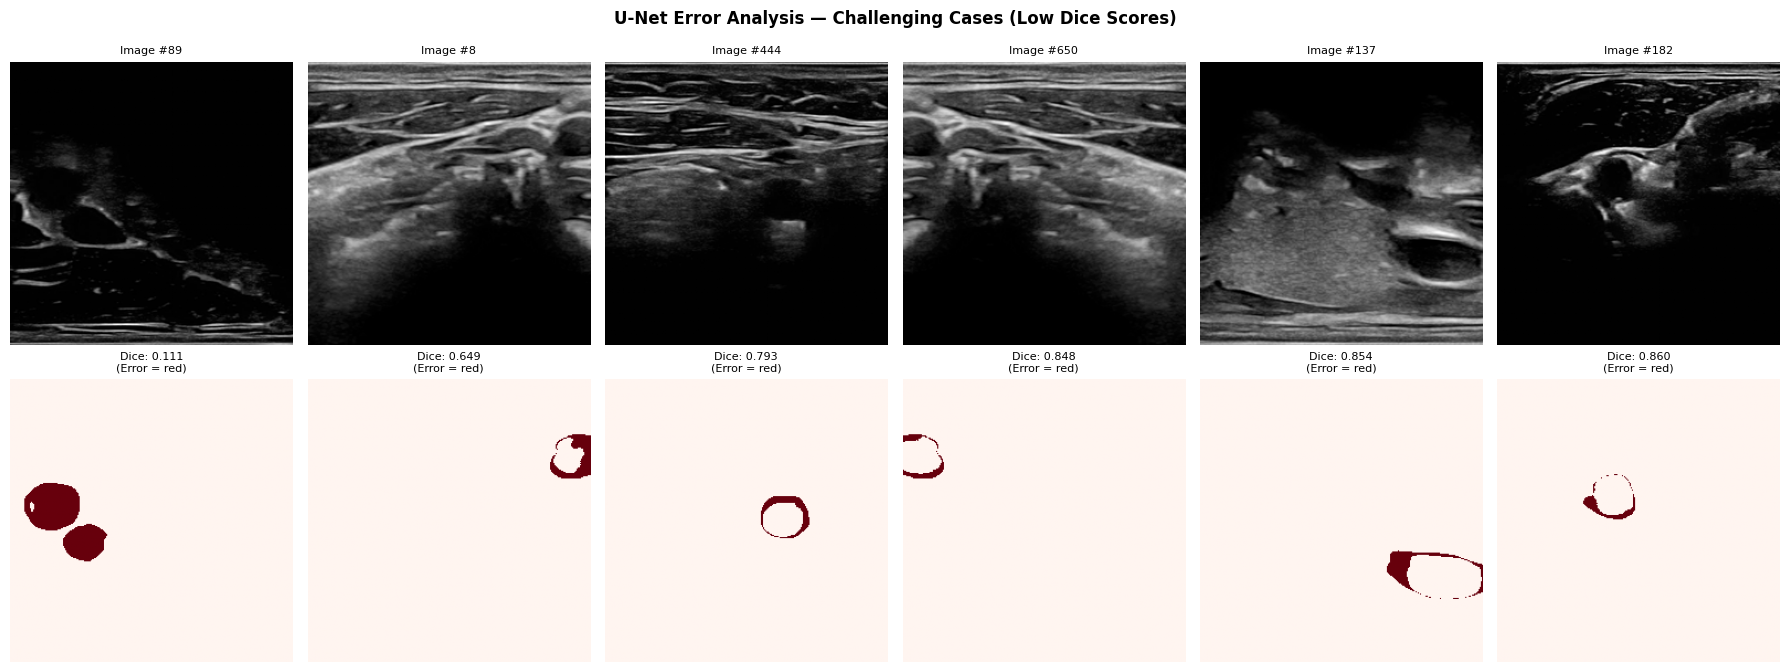

Error analysis saved!


In [21]:
# Find images with low Dice Scores (errors)
low_dice_indices = np.argsort(all_dices)[:6]  # six lowest-scoring cases

fig, axes = plt.subplots(2, 6, figsize=(18, 7))
fig.suptitle('U-Net Error Analysis — Challenging Cases (Low Dice Scores)',
             fontweight='bold', fontsize=12)

with torch.no_grad():
    for col, idx in enumerate(low_dice_indices):
        img  = test_imgs_t[idx:idx+1]
        pred = attn_unet(img).cpu().squeeze().numpy()
        true = y_test_img[idx]

        axes[0, col].imshow(X_test_img[idx], cmap='gray')
        axes[0, col].set_title(f'Image #{idx}', fontsize=8)
        axes[0, col].axis('off')

        # Error = difference between prediction and ground truth
        error_map = np.abs((pred > 0.5).astype(float) - true)
        axes[1, col].imshow(error_map, cmap='Reds', vmin=0, vmax=1)
        axes[1, col].set_title(
            f'Dice: {all_dices[idx]:.3f}\n(Error = red)',
            fontsize=8
        )
        axes[1, col].axis('off')

plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'error_analysis.png', dpi=150)
plt.show()
print("Error analysis saved!")

In [22]:
# Prepare test features
numeric_features   = ['age_years', 'ap_hi', 'ap_lo', 'bmi', 'pulse_pressure']
categoric_features = ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']

X_test_tab   = preprocessor.transform(df_test[numeric_features + categoric_features])
X_test_tfidf = tfidf.transform(df_test['risk_text'])
X_test_clin  = hstack([X_test_tab, X_test_tfidf])
y_test_clin  = df_test['cardio'].values

# Predictions
xgb_pred  = xgb.predict(X_test_clin)
xgb_proba = xgb.predict_proba(X_test_clin)[:, 1]
lr_pred   = lr_model.predict(X_test_clin)
lr_proba  = lr_model.predict_proba(X_test_clin)[:, 1]

# Evaluation metrics
results = {
    'XGBoost': {
        'Accuracy':  accuracy_score(y_test_clin, xgb_pred),
        'F1-Score':  f1_score(y_test_clin, xgb_pred),
        'AUC-ROC':   roc_auc_score(y_test_clin, xgb_proba)
    },
    'Logistic Regression': {
        'Accuracy':  accuracy_score(y_test_clin, lr_pred),
        'F1-Score':  f1_score(y_test_clin, lr_pred),
        'AUC-ROC':   roc_auc_score(y_test_clin, lr_proba)
    }
}

df_results = pd.DataFrame(results).T

print("=" * 55)
print("  CLINICAL MODEL COMPARISON TABLE — TEST SET")
print("=" * 55)
print(df_results.round(4).to_string())
print("=" * 55)
print(f"\n✅ Selected model: XGBoost (AUC-ROC: "
      f"{results['XGBoost']['AUC-ROC']:.4f})")

  CLINICAL MODEL COMPARISON TABLE — TEST SET
                     Accuracy  F1-Score  AUC-ROC
XGBoost                0.7382    0.7226    0.806
Logistic Regression    0.7271    0.7087    0.796

✅ Selected model: XGBoost (AUC-ROC: 0.8060)


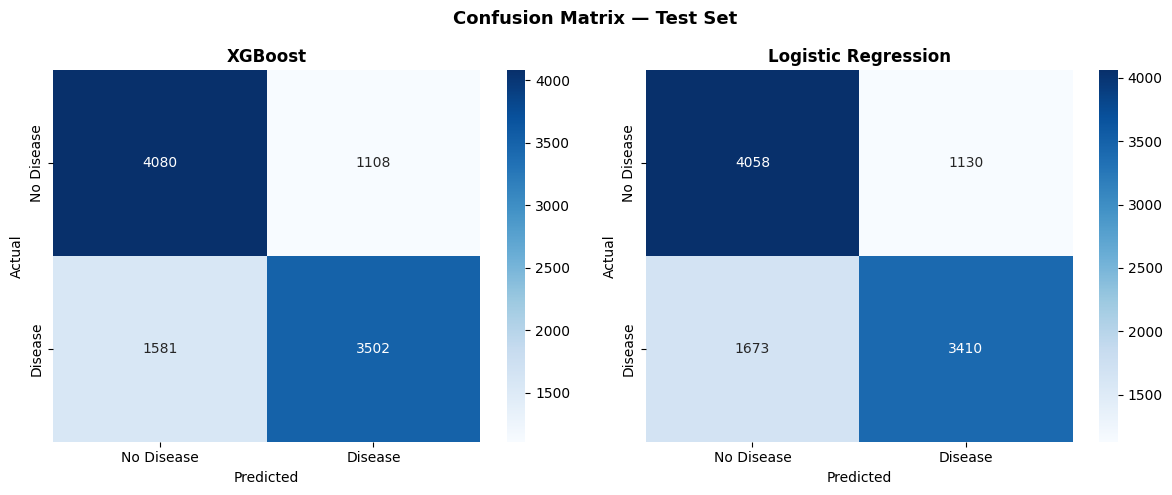

✅ Confusion matrices saved!


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Confusion Matrix — Test Set', fontweight='bold', fontsize=13)

for ax, (name, pred) in zip(
    axes,
    [('XGBoost', xgb_pred), ('Logistic Regression', lr_pred)]
):
    cm = confusion_matrix(y_test_clin, pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax,
        xticklabels=['No Disease', 'Disease'],
        yticklabels=['No Disease', 'Disease']
    )

    ax.set_title(name, fontweight='bold')
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'confusion_matrices.png', dpi=150)
plt.show()
print("✅ Confusion matrices saved!")

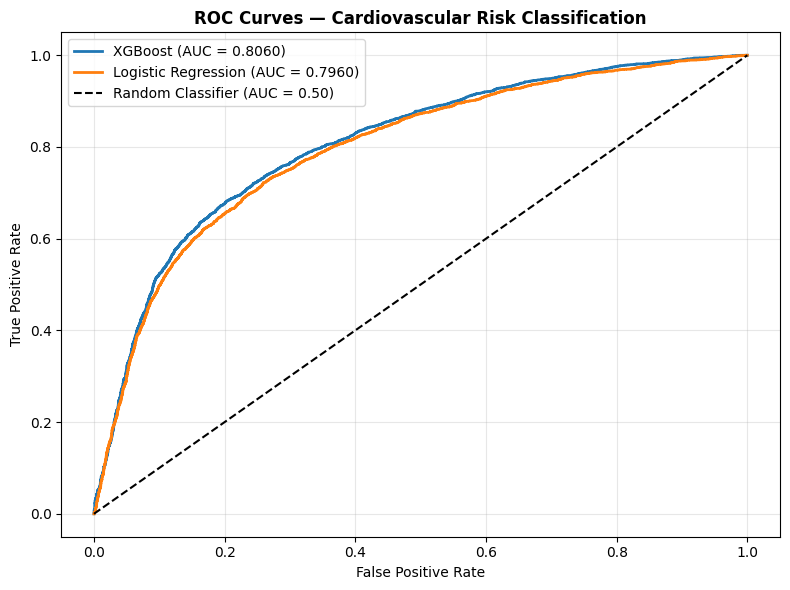

✅ ROC curves saved!


In [24]:
fig, ax = plt.subplots(figsize=(8, 6))

for name, proba in [
    ('XGBoost', xgb_proba),
    ('Logistic Regression', lr_proba)
]:
    fpr, tpr, _ = roc_curve(y_test_clin, proba)
    auc = roc_auc_score(y_test_clin, proba)

    ax.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f'{name} (AUC = {auc:.4f})'
    )

ax.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.50)')

ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title(
    'ROC Curves — Cardiovascular Risk Classification',
    fontweight='bold'
)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'roc_curves.png', dpi=150)
plt.show()
print("✅ ROC curves saved!")

In [25]:
print("""
╔══════════════════════════════════════════════════════╗
║              FINAL EVALUATION SUMMARY                ║
╠══════════════════════════════════════════════════════╣
║  COMPUTER VISION — Attention U-Net                   ║
║  • Dice Score  : {:.4f}                              ║
║  • IoU Score   : {:.4f}                              ║
╠══════════════════════════════════════════════════════╣
║  NLP + CLASSICAL ML                                  ║
║  • XGBoost     — AUC: {:.4f}  F1: {:.4f}             ║
║  • Log. Regr.  — AUC: {:.4f}  F1: {:.4f}             ║
╠══════════════════════════════════════════════════════╣
║  FINAL SELECTED MODEL: XGBoost                       ║
╚══════════════════════════════════════════════════════╝
""".format(
    mean_dice,
    mean_iou,
    results['XGBoost']['AUC-ROC'],
    results['XGBoost']['F1-Score'],
    results['Logistic Regression']['AUC-ROC'],
    results['Logistic Regression']['F1-Score']
))

# Save final results table
df_results.to_csv(OUTPUT_DIR + 'evaluation_results.csv')
print("All plots and results have been saved to the Output directory!")


╔══════════════════════════════════════════════════════╗
║              FINAL EVALUATION SUMMARY                ║
╠══════════════════════════════════════════════════════╣
║  COMPUTER VISION — Attention U-Net                   ║
║  • Dice Score  : 0.9653                              ║
║  • IoU Score   : 0.9347                              ║
╠══════════════════════════════════════════════════════╣
║  NLP + CLASSICAL ML                                  ║
║  • XGBoost     — AUC: 0.8060  F1: 0.7226             ║
║  • Log. Regr.  — AUC: 0.7960  F1: 0.7087             ║
╠══════════════════════════════════════════════════════╣
║  FINAL SELECTED MODEL: XGBoost                       ║
╚══════════════════════════════════════════════════════╝

All plots and results have been saved to the Output directory!
